In [1]:
import pandas as pd
import numpy as np

DATA_PATH = "data_final_final.csv"   # nếu bạn để cùng thư mục notebook
df = pd.read_csv(DATA_PATH)

df.shape, df.columns


((483, 30),
 Index(['stt', 'content', 'reactions', 'replies', 'posted_time', 'location',
        'contact', 'disaster_type', 'affected_people', 'infrastructure_damage',
        'needs', 'is_isolated', 'deathly', 'has_emergency_terms',
        'has_emotional_terms', 'has_emphasis', 'label', 'confident', 'tinh_tp',
        'quan_huyen', 'phuong_xa', 'nha', 'chỗ ở & nơi trú ẩn',
        'liên lạc & thông tin', 'lương thực & nước uống',
        'phương tiện & cứu hộ', 'thuốc men & hỗ trợ y tế',
        'vật dụng sinh hoạt (áo phao, đèn pin, quần áo, mền chăn)',
        'affected_people_log', 'affected_people_minmax'],
       dtype='object'))

In [2]:
TARGET_COL = "label"  # trong dataset của bạn

# Làm sạch nhãn để tránh kiểu "Cao" vs "CAO", "Trung Bình" vs "TRUNG BÌNH"
y = (
    df[TARGET_COL].astype(str).str.strip()
      .str.replace(r"\s+", " ", regex=True)
      .str.upper()
)
y = y.replace({"TRUNG BINH": "TRUNG BÌNH", "THAP": "THẤP"})

# X: bỏ target và bỏ các cột không muốn dùng
drop_cols = [TARGET_COL]
# nên bỏ "stt" vì là chỉ số
if "stt" in df.columns: drop_cols.append("stt")

X = df.drop(columns=drop_cols)

y.value_counts()


label
CAO           253
TRUNG BÌNH    159
THẤP           71
Name: count, dtype: int64

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 70/15/15: tách test trước (15%), sau đó tách val từ phần train còn lại
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1765, random_state=42, stratify=y_train_full
)
# 0.1765 * 0.85 ≈ 0.15

# Encode y về số (LightGBM/Sklearn cần)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_val_enc   = le.transform(y_val)
y_test_enc  = le.transform(y_test)

classes = list(le.classes_)
classes


['CAO', 'THẤP', 'TRUNG BÌNH']

In [4]:
# Fill missing đơn giản
X_train2 = X_train.copy()
X_val2   = X_val.copy()
X_test2  = X_test.copy()

# Xác định cột categorical (object) và numeric
cat_cols = [c for c in X_train2.columns if X_train2[c].dtype == "object"]
num_cols = [c for c in X_train2.columns if X_train2[c].dtype != "object"]

def basic_impute_and_cast(df_):
    df_ = df_.copy()
    for c in cat_cols:
        df_[c] = df_[c].fillna("MISSING").astype("category")
    for c in num_cols:
        df_[c] = df_[c].fillna(df_[c].median())
    return df_

X_train2 = basic_impute_and_cast(X_train2)
X_val2   = basic_impute_and_cast(X_val2)
X_test2  = basic_impute_and_cast(X_test2)

cat_cols


['content',
 'posted_time',
 'location',
 'needs',
 'confident',
 'tinh_tp',
 'quan_huyen',
 'phuong_xa',
 'nha']

In [7]:
!pip install lightgbm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 911.4 kB/s  0:00:03 eta 0:00:01


In [16]:
import re

def sanitize_columns(df):
    used = set()
    new_cols = []
    for col in df.columns:
        s = str(col).replace("\n"," ").replace("\r"," ").replace("\t"," ")
        s = re.sub(r"[^0-9A-Za-z_]+", "_", s)      # chỉ giữ chữ/số/_
        s = re.sub(r"_+", "_", s).strip("_")       # gộp _
        if s == "":
            s = "col"
        base = s
        k = 1
        while s in used:
            k += 1
            s = f"{base}_{k}"
        used.add(s)
        new_cols.append(s)
    df = df.copy()
    df.columns = new_cols
    return df

df = sanitize_columns(df)
df.columns[:30]


Index(['stt', 'content', 'reactions', 'replies', 'posted_time', 'location',
       'contact', 'disaster_type', 'affected_people', 'infrastructure_damage',
       'needs', 'is_isolated', 'deathly', 'has_emergency_terms',
       'has_emotional_terms', 'has_emphasis', 'label', 'confident', 'tinh_tp',
       'quan_huyen', 'phuong_xa', 'nha', 'ch_n_i_tr_n', 'li_n_l_c_th_ng_tin',
       'l_ng_th_c_n_c_u_ng', 'ph_ng_ti_n_c_u_h', 'thu_c_men_h_tr_y_t',
       'v_t_d_ng_sinh_ho_t_o_phao_n_pin_qu_n_o_m_n_ch_n',
       'affected_people_log', 'affected_people_minmax'],
      dtype='object')

In [17]:
TARGET_COL = "label"

y = df[TARGET_COL].astype(str).str.strip().str.upper()
X = df.drop(columns=[TARGET_COL] + ([c for c in ["stt","id","ID"] if c in df.columns]))

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1765, random_state=42, stratify=y_train_full
)

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_val_enc   = le.transform(y_val)
y_test_enc  = le.transform(y_test)

cat_cols = [c for c in X_train.columns if X_train[c].dtype == "object"]
num_cols = [c for c in X_train.columns if X_train[c].dtype != "object"]


In [18]:
import lightgbm as lgb

for c in cat_cols:
    X_train[c] = X_train[c].fillna("MISSING").astype("category")
    X_val[c]   = X_val[c].fillna("MISSING").astype("category")
    X_test[c]  = X_test[c].fillna("MISSING").astype("category")

for c in num_cols:
    med = X_train[c].median()
    X_train[c] = X_train[c].fillna(med)
    X_val[c]   = X_val[c].fillna(med)
    X_test[c]  = X_test[c].fillna(med)

classes = le.classes_
n_classes = len(classes)

model = lgb.LGBMClassifier(
    objective="multiclass",
    num_class=n_classes,
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

evals_result = {}
model.fit(
    X_train, y_train_enc,
    eval_set=[(X_val, y_val_enc)],
    eval_metric="multi_logloss",
    categorical_feature=cat_cols,
    callbacks=[
        lgb.early_stopping(stopping_rounds=100, verbose=True),
        lgb.record_evaluation(evals_result)
    ]
)

model.best_iteration_


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000153 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 178
[LightGBM] [Info] Number of data points in the train set: 337, number of used features: 25
[LightGBM] [Info] Start training from score -0.643933
[LightGBM] [Info] Start training from score -1.928263
[LightGBM] [Info] Start training from score -1.110553
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 100 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits w

39

In [19]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

def evaluate_split(name, Xs, ys_enc):
    pred = model.predict(Xs)
    acc = accuracy_score(ys_enc, pred)
    p, r, f1, _ = precision_recall_fscore_support(ys_enc, pred, average="macro", zero_division=0)
    print(f"{name}: Accuracy={acc:.4f} | Precision_macro={p:.4f} | Recall_macro={r:.4f} | F1_macro={f1:.4f}")
    return pred

pred_train = evaluate_split("TRAIN", X_train2, y_train_enc)
pred_val   = evaluate_split("VAL  ", X_val2, y_val_enc)
pred_test  = evaluate_split("TEST ", X_test2, y_test_enc)

print("\nClassification report (TEST):")
print(classification_report(y_test_enc, pred_test, target_names=classes, digits=4, zero_division=0))


TRAIN: Accuracy=0.7240 | Precision_macro=0.7062 | Recall_macro=0.6564 | F1_macro=0.6747
VAL  : Accuracy=0.6438 | Precision_macro=0.5610 | Recall_macro=0.5485 | F1_macro=0.5514
TEST : Accuracy=0.5890 | Precision_macro=0.5565 | Recall_macro=0.5134 | F1_macro=0.5216

Classification report (TEST):
              precision    recall  f1-score   support

         CAO     0.7027    0.6842    0.6933        38
        THẤP     0.5000    0.2727    0.3529        11
  TRUNG BÌNH     0.4667    0.5833    0.5185        24

    accuracy                         0.5890        73
   macro avg     0.5565    0.5134    0.5216        73
weighted avg     0.5946    0.5890    0.5846        73



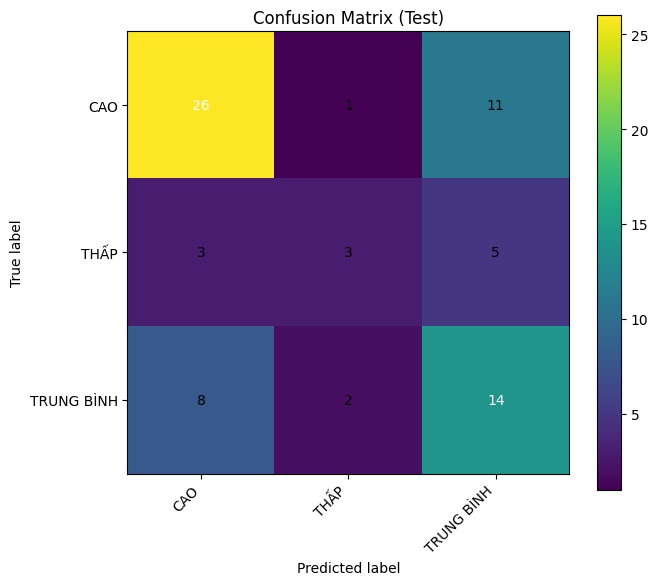

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_enc, pred_test)

plt.figure(figsize=(7,6))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix (Test)")
plt.colorbar()

ticks = np.arange(len(classes))
plt.xticks(ticks, classes, rotation=45, ha="right")
plt.yticks(ticks, classes)

plt.ylabel("True label")
plt.xlabel("Predicted label")

thresh = cm.max() / 2 if cm.max() else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.tight_layout()
plt.show()


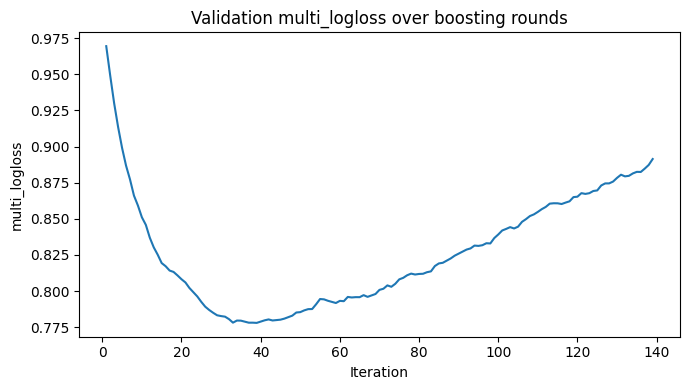

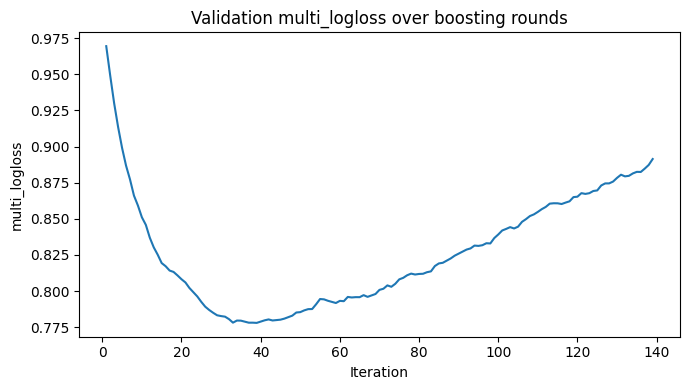

In [21]:
# evals_result["valid_0"]["multi_logloss"] là danh sách logloss qua từng vòng
vals = evals_result.get("valid_0", {}).get("multi_logloss", None)

if vals is not None:
    plt.figure(figsize=(7,4))
    plt.plot(np.arange(1, len(vals)+1), vals)
    plt.title("Validation multi_logloss over boosting rounds")
    plt.xlabel("Iteration")
    plt.ylabel("multi_logloss")
    plt.tight_layout()
    plt.show()
else:
    print("Không có evals_result để vẽ (hãy chắc rằng bạn đã dùng record_evaluation callback).")
# evals_result["valid_0"]["multi_logloss"] là danh sách logloss qua từng vòng
vals = evals_result.get("valid_0", {}).get("multi_logloss", None)

if vals is not None:
    plt.figure(figsize=(7,4))
    plt.plot(np.arange(1, len(vals)+1), vals)
    plt.title("Validation multi_logloss over boosting rounds")
    plt.xlabel("Iteration")
    plt.ylabel("multi_logloss")
    plt.tight_layout()
    plt.show()
else:
    print("Không có evals_result để vẽ (hãy chắc rằng bạn đã dùng record_evaluation callback).")


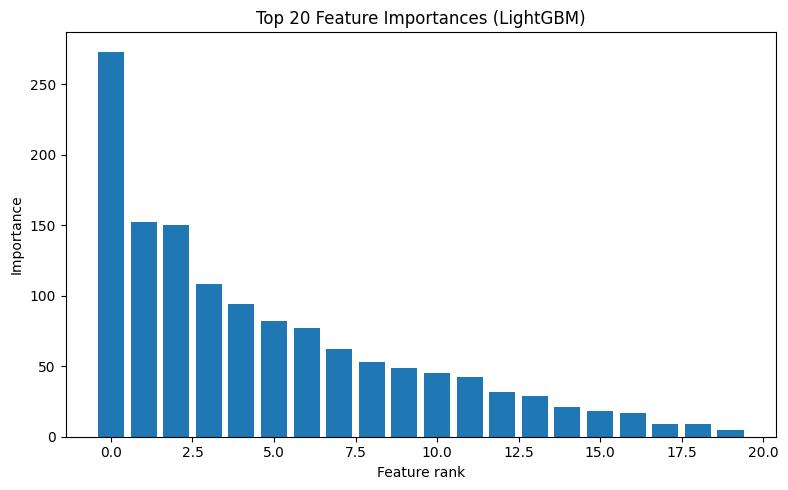

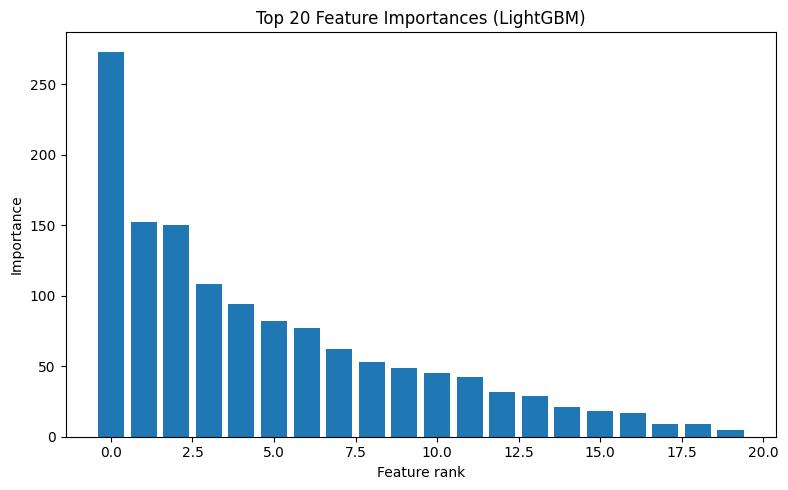

[('affected_people', 273),
 ('confident', 152),
 ('li_n_l_c_th_ng_tin', 150),
 ('deathly', 108),
 ('has_emergency_terms', 94),
 ('infrastructure_damage', 82),
 ('contact', 77),
 ('ph_ng_ti_n_c_u_h', 62),
 ('l_ng_th_c_n_c_u_ng', 53),
 ('thu_c_men_h_tr_y_t', 49)]

In [22]:
importances = model.feature_importances_
feat_names = model.feature_name_

# Top 20
topk = 20
idx = np.argsort(importances)[::-1][:topk]

plt.figure(figsize=(8,5))
plt.bar(np.arange(topk), importances[idx])
plt.title("Top 20 Feature Importances (LightGBM)")
plt.xlabel("Feature rank")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

# In tên top feature
top_features = [(feat_names[i], int(importances[i])) for i in idx]
top_features[:10]
importances = model.feature_importances_
feat_names = model.feature_name_

# Top 20
topk = 20
idx = np.argsort(importances)[::-1][:topk]

plt.figure(figsize=(8,5))
plt.bar(np.arange(topk), importances[idx])
plt.title("Top 20 Feature Importances (LightGBM)")
plt.xlabel("Feature rank")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

# In tên top feature
top_features = [(feat_names[i], int(importances[i])) for i in idx]
top_features[:10]


In [23]:
from sklearn.metrics import accuracy_score

train_accuracy = accuracy_score(y_train_enc, model.predict(X_train2))
val_accuracy   = accuracy_score(y_val_enc,   model.predict(X_val2))
test_accuracy  = accuracy_score(y_test_enc,  model.predict(X_test2))

print("train_accuracy =", train_accuracy)
print("val_accuracy   =", val_accuracy)
print("test_accuracy  =", test_accuracy)


train_accuracy = 0.7240356083086054
val_accuracy   = 0.6438356164383562
test_accuracy  = 0.589041095890411
